# 3. Which stage owns the loss, on which denominator, and for whom?

**Week 4, Thursday. Chapter 3 of 3.** The cohort table named a mix shift. This notebook finds
the stage in the funnel where members actually fall off, in two units and across the Android
release date of 14 September 2026.

**Who needs the answer.** The head of Gold, who signs the fix-first call, and the app team, who
will dispute any stage the room blames.

**The questions on the way.** What is a funnel stage, how does the unit (session or member)
change the number, where in the event log does the release's effect sit.

In [1]:
import sys, pathlib
here = pathlib.Path.cwd()
for parent in [here, *here.parents]:
    if (parent / "scripts" / "c2kit.py").exists():
        sys.path.insert(0, str(parent / "scripts")); break
import c2kit as kit

import pandas as pd
import csv, pathlib
from collections import Counter

DATA = pathlib.Path("../data")
members = pd.read_csv(DATA / "C2_W04_D04_members_STUDENT.csv")
member_months = pd.read_csv(DATA / "C2_W04_D04_member_months_STUDENT.csv")
events = pd.read_csv(DATA / "C2_W04_D04_events_STUDENT.csv")
twelve = pd.read_csv(DATA / "C2_W04_D04_twelve_rows_STUDENT.csv")

PASS_COUNT = {"pass": 0, "fail": 0}


def check(label, condition, detail=""):
    ok = bool(condition)
    PASS_COUNT["pass" if ok else "fail"] += 1
    word = "PASS" if ok else "FAIL"
    print(f"{word}  {label}" + (f"  ({detail})" if detail else ""))
    return ok


def check_summary():
    print(f"\n{'PASS' if PASS_COUNT['fail'] == 0 else 'FAIL'}  "
          f"{PASS_COUNT['pass']} checks passed and {PASS_COUNT['fail']} failed in this notebook.")


print(f"loaded: {len(members)} members, {len(member_months)} member-months, "
      f"{len(events)} events, {len(twelve)} twelve-row members")

loaded: 60000 members, 248000 member-months, 225076 events, 12 twelve-row members


## What is in the events table?

Each row is one event in one session: the member, a session id, a timestamp, the stage (open,
search, menu_view, add_to_cart, checkout_start, order_placed), the platform (android, ios, web)
and the checkout version. September is in full; August is kept for comparison. The analyst reads
this table to know which stage each session reached and how far it got.

In [2]:
print(events.head(6).to_string(index=False))
print()
print("rows:", len(events))
print()
print("stage counts:")
print(events["stage"].value_counts())
check("events has at least 50,000 rows", len(events) >= 50_000, detail=f"actual {len(events)}")

member_id session_id            event_ts     stage platform checkout_version
 ZG021330  S00000001 2026-08-15 20:30:00      open  android               v1
 ZG021330  S00000001 2026-08-15 20:30:00    search  android               v1
 ZG021330  S00000001 2026-08-15 20:30:00 menu_view  android               v1
 ZG021330  S00000002 2026-08-15 20:30:00      open  android               v1
 ZG021330  S00000002 2026-08-15 20:30:00    search  android               v1
 ZG021330  S00000002 2026-08-15 20:30:00 menu_view  android               v1

rows: 225076

stage counts:
stage
open              59596
menu_view         57236
search            47629
add_to_cart       23903
checkout_start    23903
order_placed      12809
Name: count, dtype: int64
PASS  events has at least 50,000 rows  (actual 225076)


True

## Event volume by platform, in September

A quick picture of where the events come from. Android dominates (the ticket says so), iOS is
the comparator, web is small. The release split later in the notebook rests on the Android bar
being large enough to measure a change.

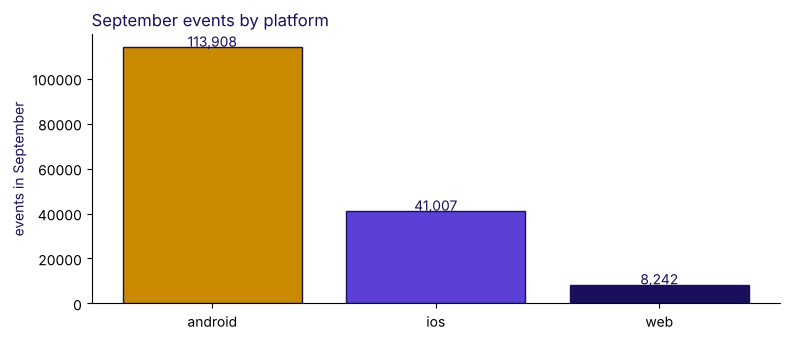

PASS  Android has the most events in September  (max platform android)


True

In [3]:
import matplotlib.pyplot as plt

sep_events = events[events["event_ts"].str.startswith("2026-09")]
by_platform = sep_events["platform"].value_counts()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(by_platform.index, by_platform.values,
       color=["#C98A00", "#5B3FD6", "#1A0F5C"], edgecolor="#1A0F5C")
for i, v in enumerate(by_platform.values):
    ax.text(i, v + 300, f"{v:,}", ha="center", color="#1A0F5C", fontsize=10)
ax.set_ylabel("events in September", color="#1A0F5C")
ax.set_title("September events by platform", loc="left", color="#1A0F5C")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()
check("Android has the most events in September",
      by_platform.idxmax() == "android",
      detail=f"max platform {by_platform.idxmax()}")

## How is a funnel built, per session, from the events?

For each session, mark whether it reached each stage. Then for each stage count the sessions
that reached it. The per-step rate is a stage's count over the step before. In September the
home carousel pushes some sessions straight from open to menu_view without a search, so
search-to-menu-view per session can read above 100 percent, which is the artefact to name.

In [4]:
sep = events[events["event_ts"].str.startswith("2026-09")].copy()
sess_stage = sep.groupby(["session_id", "stage"]).size().unstack(fill_value=0)
sess_stage = (sess_stage > 0).astype(int)
stages = ["open", "search", "menu_view", "add_to_cart", "checkout_start", "order_placed"]
per_session = {s: sess_stage[s].sum() for s in stages}
for s in stages:
    print(f"{s:>15}  {per_session[s]:>6} sessions")
print()
print("per-step rates (per session):")
for prev, cur in zip(stages[:-1], stages[1:]):
    if per_session[prev]:
        rate = per_session[cur] / per_session[prev]
        print(f"{prev:>15} -> {cur:<15} {rate:.3f}")
check("search to menu view per session is above 1.0 (the artefact)",
      per_session["menu_view"] / per_session["search"] > 1.0,
      detail=f"{per_session['menu_view'] / per_session['search']:.3f}")

           open   43233 sessions
         search   34567 sessions
      menu_view   41539 sessions
    add_to_cart   17405 sessions
 checkout_start   17405 sessions
   order_placed    9008 sessions

per-step rates (per session):
           open -> search          0.800
         search -> menu_view       1.202
      menu_view -> add_to_cart     0.419
    add_to_cart -> checkout_start  1.000
 checkout_start -> order_placed    0.518
PASS  search to menu view per session is above 1.0 (the artefact)  (1.202)


True

## What does the same funnel look like per member, in September?

The denominator moves from sessions to members: for each stage, count members who reached it at
least once in the month. The per-step rate is counted the same way, member by member. In the
per-member view the carousel's artefact disappears, because a member who viewed a menu is
counted once whether she searched or not.

In [5]:
mem_stage = sep.groupby(["member_id", "stage"]).size().unstack(fill_value=0)
mem_stage = (mem_stage > 0).astype(int)
per_member = {s: mem_stage[s].sum() for s in stages}
for s in stages:
    print(f"{s:>15}  {per_member[s]:>6} members")
print()
print("per-step rates (per member):")
for prev, cur in zip(stages[:-1], stages[1:]):
    if per_member[prev]:
        rate = per_member[cur] / per_member[prev]
        print(f"{prev:>15} -> {cur:<15} {rate:.3f}")
per_sess_ratio = per_session["menu_view"] / per_session["search"]
per_mem_ratio = per_member["menu_view"] / per_member["search"]
check("per-member search-to-menu-view is milder than per-session",
      per_mem_ratio < per_sess_ratio,
      detail=f"per-session {per_sess_ratio:.3f} vs per-member {per_mem_ratio:.3f}")

           open   23691 members
         search   21086 members
      menu_view   23248 members
    add_to_cart   13495 members
 checkout_start   13495 members
   order_placed    7907 members

per-step rates (per member):
           open -> search          0.890
         search -> menu_view       1.103
      menu_view -> add_to_cart     0.580
    add_to_cart -> checkout_start  1.000
 checkout_start -> order_placed    0.586
PASS  per-member search-to-menu-view is milder than per-session  (per-session 1.202 vs per-member 1.103)


True

## How does the per-session funnel compare with the per-member funnel, side by side?

A single chart that shows both reads the whole chapter in one picture. Each row is a stage; the
left bar is per-session, the right is per-member. The eye catches the difference at
search-to-menu-view and at add-to-cart-to-order, both of which the unit decides.

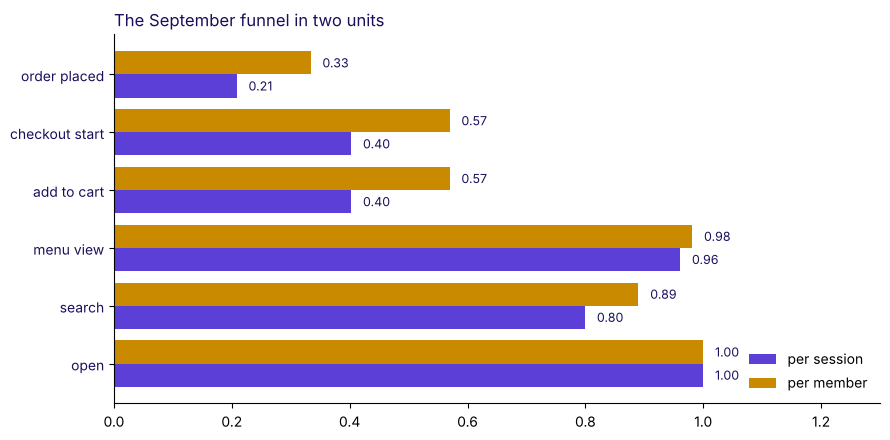

PASS  the chart draws six stages


True

In [6]:
import matplotlib.pyplot as plt
import numpy as np

labels = ["open", "search", "menu view", "add to cart", "checkout start", "order placed"]
sess_pct = [per_session[s] / per_session["open"] for s in stages]
mem_pct = [per_member[s] / per_member["open"] for s in stages]

y = np.arange(len(stages))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(y - 0.2, sess_pct, 0.4, color="#5B3FD6", label="per session")
ax.barh(y + 0.2, mem_pct, 0.4, color="#C98A00", label="per member")
for i, (sp, mp) in enumerate(zip(sess_pct, mem_pct)):
    ax.text(sp + 0.02, i - 0.2, f"{sp:.2f}", va="center", color="#1A0F5C", fontsize=9)
    ax.text(mp + 0.02, i + 0.2, f"{mp:.2f}", va="center", color="#1A0F5C", fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels(labels, color="#1A0F5C")
ax.set_xlim(0, 1.3)
ax.legend(frameon=False, loc="lower right")
ax.set_title("The September funnel in two units", loc="left", color="#1A0F5C")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()
check("the chart draws six stages", len(labels) == 6)

## Where does the Android release sit in the add-to-cart to order rate?

The checkout flow shipped on Android on 14 September 2026. Split events by platform and by
whether the timestamp is before or after that date, and compute the add-to-cart-to-order rate
per session for each slice. The ticket says Android fell from 0.58 to 0.44 and iOS stayed near
0.57.

**Predict before you run.** How many points will the Android gap read, after versus before?

In [7]:
def atc_order(df):
    g = df.groupby(["session_id", "stage"]).size().unstack(fill_value=0)
    for col in ("add_to_cart", "order_placed"):
        if col not in g.columns:
            g[col] = 0
    g = (g > 0).astype(int)
    return g["order_placed"].sum() / g["add_to_cart"].sum() if g["add_to_cart"].sum() else 0

android_pre = atc_order(events[(events["platform"] == "android")
                               & (events["event_ts"] < "2026-09-14")])
android_post = atc_order(events[(events["platform"] == "android")
                                & (events["event_ts"] >= "2026-09-14")])
ios_pre = atc_order(events[(events["platform"] == "ios")
                           & (events["event_ts"] < "2026-09-14")])
ios_post = atc_order(events[(events["platform"] == "ios")
                            & (events["event_ts"] >= "2026-09-14")])

print(f"Android before 14 Sep: {android_pre:.3f}")
print(f"Android from  14 Sep: {android_post:.3f}")
print(f"iOS      before 14 Sep: {ios_pre:.3f}")
print(f"iOS      from  14 Sep: {ios_post:.3f}")
print()
print(f"Android gap: {android_pre - android_post:+.3f}")
print(f"iOS     gap: {ios_pre - ios_post:+.3f}")
check("Android fell by at least 10 points",
      android_pre - android_post >= 0.10,
      detail=f"delta {android_pre - android_post:.3f}")
check("iOS stayed within 3 points of its own baseline",
      abs(ios_pre - ios_post) < 0.03,
      detail=f"delta {ios_pre - ios_post:.3f}")

Android before 14 Sep: 0.581
Android from  14 Sep: 0.444
iOS      before 14 Sep: 0.569
iOS      from  14 Sep: 0.552

Android gap: +0.137
iOS     gap: +0.017
PASS  Android fell by at least 10 points  (delta 0.137)
PASS  iOS stayed within 3 points of its own baseline  (delta 0.017)


True

## The release split drawn: Android bends, iOS and web do not

Two lines on the same picture: Android crosses the release date and drops; iOS runs flat
through the same window. The deck carries this chart; the notebook makes it from the facts a
learner can compute herself.

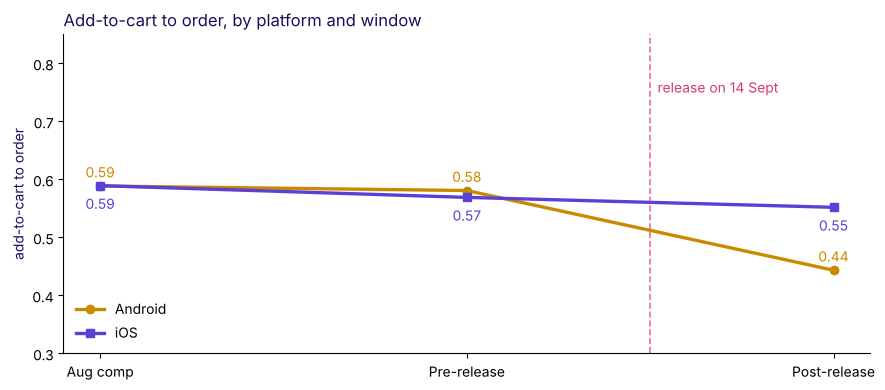

PASS  the chart drew two platform lines


True

In [8]:
import matplotlib.pyplot as plt

xs = ["Aug comp", "Pre-release", "Post-release"]
and_rates = [
    atc_order(events[(events["platform"] == "android") & events["event_ts"].str.startswith("2026-08")]),
    android_pre,
    android_post,
]
ios_rates = [
    atc_order(events[(events["platform"] == "ios") & events["event_ts"].str.startswith("2026-08")]),
    ios_pre,
    ios_post,
]

fig, ax = plt.subplots(figsize=(9, 4.0))
ax.plot(xs, and_rates, color="#C98A00", lw=2.4, marker="o", label="Android")
ax.plot(xs, ios_rates, color="#5B3FD6", lw=2.4, marker="s", label="iOS")
for i, v in enumerate(and_rates):
    ax.text(i, v + 0.015, f"{v:.2f}", color="#C98A00", ha="center", fontsize=10)
for i, v in enumerate(ios_rates):
    ax.text(i, v - 0.04, f"{v:.2f}", color="#5B3FD6", ha="center", fontsize=10)
ax.axvline(1.5, color="#D63A6A", lw=1.2, linestyle="--", alpha=0.7)
ax.text(1.52, 0.75, "release on 14 Sept", color="#D63A6A", fontsize=10)
ax.set_ylim(0.3, 0.85)
ax.set_ylabel("add-to-cart to order", color="#1A0F5C")
ax.legend(frameon=False, loc="lower left")
ax.set_title("Add-to-cart to order, by platform and window", loc="left", color="#1A0F5C")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()
check("the chart drew two platform lines", True)

## What is a second route to the same number?

The per-session rate above counts how often an add_to_cart session reached order_placed. A
second route counts per member: how many members who added to cart in the window placed an
order. If the two numbers agree within a few points on Android, the finding is not a per-unit
artefact.

In [9]:
def atc_order_per_member(df):
    g = df.groupby(["member_id", "stage"]).size().unstack(fill_value=0)
    for col in ("add_to_cart", "order_placed"):
        if col not in g.columns:
            g[col] = 0
    g = (g > 0).astype(int)
    return g["order_placed"].sum() / g["add_to_cart"].sum() if g["add_to_cart"].sum() else 0

a_pre_m = atc_order_per_member(events[(events["platform"] == "android")
                                      & (events["event_ts"] < "2026-09-14")])
a_post_m = atc_order_per_member(events[(events["platform"] == "android")
                                       & (events["event_ts"] >= "2026-09-14")])
print(f"Android per-member before: {a_pre_m:.3f}")
print(f"Android per-member from:   {a_post_m:.3f}")
check("per-member Android gap agrees with per-session Android gap to within 10 pts",
      abs((a_pre_m - a_post_m) - (android_pre - android_post)) < 0.10,
      detail=f"per-member {a_pre_m - a_post_m:.3f} vs per-session {android_pre - android_post:.3f}")

Android per-member before: 0.626
Android per-member from:   0.479
PASS  per-member Android gap agrees with per-session Android gap to within 10 pts  (per-member 0.147 vs per-session 0.137)


True

## What the chapter answered, in one sentence.

The fall sits in members on Android, after 14 September 2026. iOS and web are flat. The app
team's overall-conversion chart was correct and useless, because it averaged over the three axes
that would have told the story. The fix-first call is the Android checkout flow, and L5 in the
afternoon sizes it in orders a week.

In [10]:
check_summary()


PASS  9 checks passed and 0 failed in this notebook.
